# Применение условных вероятностей в анализе данных
Для исследования возьмём набор данных **Breast Cancer Wisconsin (Diagnostic)**: по характеристикам опухоли нужно оценить вероятность того, что она злокачественная.

## Описание набора данных
---
* **Источник:** Kaggle / UCI Machine Learning Repository, [Breast Cancer Wisconsin (Diagnostic)](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data).
* **Назначение:** диагностика рака молочной железы - по характеристикам клеточных ядер определить, является опухоль злокачественной (**M**, malignant) или доброкачественной (**B**, benign).
* **Объём:** 569 пациентов. Признаки вычислены по оцифрованным снимкам тонкоигольной аспирационной биопсии.
* **Признаки:** для каждого из 10 свойств клеточных ядер считаются 3 значения: среднее (`mean`), стандартная ошибка (`error`) и «наихудшее» значение (`worst` - среднее из трёх наибольших), всего 30 числовых признаков.

| Свойство | Описание |
|---|---|
| radius | радиус (среднее расстояние от центра ядра до его границы) |
| texture | текстура (стандартное отклонение значений серого цвета) |
| perimeter | периметр ядра |
| area | площадь ядра |
| smoothness | гладкость (локальные изменения длин радиусов) |
| compactness | компактность ($\frac{perimeter^2}{area} - 1$) |
| concavity | вогнутость (степень вогнутости контура) |
| concave points | число вогнутых участков контура |
| symmetry | симметричность |
| fractal dimension | фрактальная размерность («береговая линия» - 1) |

Целевой признак `diagnosis`: **M** - злокачественная опухоль, **B** - доброкачественная.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

pd.options.display.float_format = '{:.4f}'.format
%matplotlib inline

## Загрузка данных
---
Берём тот же набор данных из библиотеки sklearn, чтобы не скачивать файл вручную. В sklearn целевой признак закодирован числами (0 - злокачественная, 1 - доброкачественная), поэтому заменим его на метки **M** и **B**, как в версии с Kaggle.

In [21]:
data = load_breast_cancer(as_frame=True)
df = data.frame
df['diagnosis'] = df['target'].map({0: 'M', 1: 'B'})
df = df.drop(columns='target')

print("Размерность данных:", df.shape)
print("Пропусков в данных:", df.isna().sum().sum())
df[['mean radius', 'mean texture', 'mean area', 'mean concavity', 'diagnosis']].head()

Размерность данных: (569, 31)
Пропусков в данных: 0


,mean radius,mean texture,mean area,mean concavity,diagnosis
0,17.9900,10.3800,1001.0000,0.3001,M
1,20.5700,17.7700,1326.0000,0.0869,M
2,19.6900,21.2500,1203.0000,0.1974,M
3,11.4200,20.3800,386.1000,0.2414,M
4,20.2900,14.3400,1297.0000,0.1980,M


## Подготовка признаков
---
Условные вероятности считаются для событий, поэтому непрерывные признаки разобьём на категории. Возьмём два легко интерпретируемых признака:
* **размер опухоли** (по `mean radius`): малый ($< 12$), средний ($12 - 16$), крупный ($\geq 16$);
* **вогнутость контура** (по `mean concavity`): низкая ($< 0.05$), средняя ($0.05 - 0.10$), высокая ($\geq 0.10$).

In [22]:
df['size'] = pd.cut(df['mean radius'], bins=[0, 12, 16, np.inf],
                    labels=['малый', 'средний', 'крупный'], right=False)
df['concavity'] = pd.cut(df['mean concavity'], bins=[0, 0.05, 0.10, np.inf],
                         labels=['низкая', 'средняя', 'высокая'], right=False)

df['malignant'] = df['diagnosis'] == 'M'

P_M = df['malignant'].mean()
print(f"Безусловная вероятность злокачественной опухоли P(M) = {P_M:.4f}")

Безусловная вероятность злокачественной опухоли P(M) = 0.3726


## 1. Условная вероятность
---
Пусть $A$ - событие «опухоль злокачественная», $B$ - некоторое условие (например, «опухоль крупная»). Условная вероятность события $A$ при условии, что произошло $B$:

$$P_B(A) = \frac{P(A \cdot B)}{P(B)} = \frac{N(A \cdot B)}{N(B)},$$

где $N(A \cdot B)$ - число объектов, для которых выполнены оба события, $N(B)$ - число объектов, для которых выполнено $B$.<br>
Посчитаем $P_{\text{размер}}(M)$ для каждой категории размера и расположим категории по убыванию вероятности.

In [23]:
ct = pd.crosstab(df['size'], df['diagnosis'])
ct.columns.name = None
ct['Всего'] = ct['B'] + ct['M']
ct['P(M | размер)'] = ct['M'] / ct['Всего']
ct.sort_values('P(M | размер)', ascending=False)

,B,M,Всего,P(M | размер)
size,,,,
крупный,6,135,141,0.9574
средний,188,71,259,0.2741
малый,163,6,169,0.0355


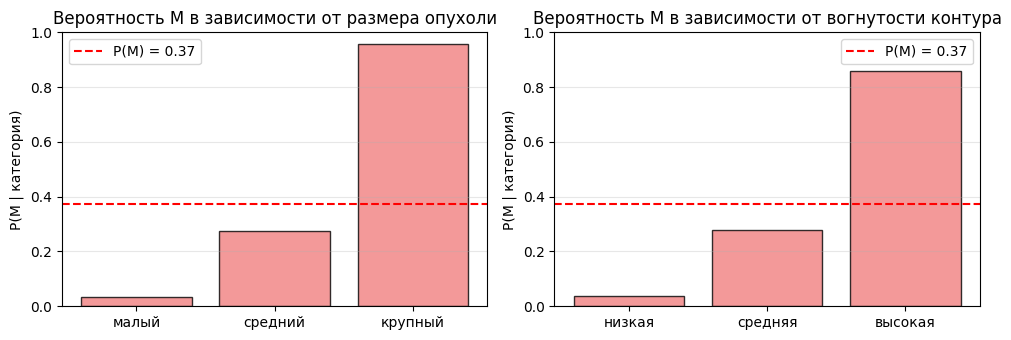

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

for ax, feature, name in [(ax1, 'size', 'размера опухоли'), (ax2, 'concavity', 'вогнутости контура')]:
    p = df.groupby(feature, observed=True)['malignant'].mean()
    ax.bar(p.index.astype(str), p.values, color='lightcoral', edgecolor='black', alpha=0.8)
    ax.axhline(P_M, color='RED', linestyle='--', label=f'P(M) = {P_M:.2f}')
    ax.set_title(f'Вероятность M в зависимости от {name}')
    ax.set_ylabel('P(M | категория)')
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Вероятность злокачественной опухоли резко зависит от условия: для малых опухолей она намного ниже безусловной $P(M)$, а для крупных - почти равна единице. То же самое видно и для вогнутости контура.

### Два условия одновременно
Условие может быть пересечением событий. Найдём $P_{B_1 \cdot B_2}(M)$, где $B_1$ - размер опухоли, $B_2$ - вогнутость контура.

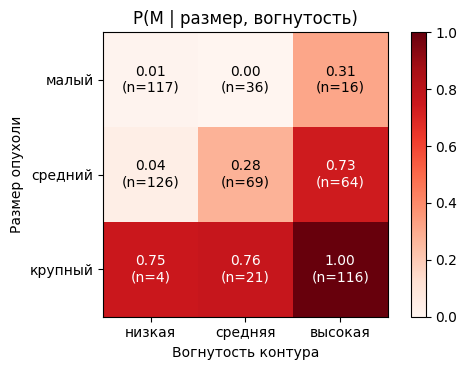

In [25]:
order_size = ['малый', 'средний', 'крупный']
order_conc = ['низкая', 'средняя', 'высокая']

pivot = df.pivot_table(index='size', columns='concavity', values='malignant', aggfunc='mean', observed=True)
cnt = df.pivot_table(index='size', columns='concavity', values='malignant', aggfunc='count', observed=True)
pivot = pivot.loc[order_size, order_conc]
cnt = cnt.loc[order_size, order_conc]

fig, ax = plt.subplots(figsize=(5.5, 3.8))
im = ax.imshow(pivot.values, cmap='Reds', vmin=0, vmax=1)
ax.set_xticks(range(3))
ax.set_xticklabels(order_conc)
ax.set_yticks(range(3))
ax.set_yticklabels(order_size)
ax.set_xlabel('Вогнутость контура')
ax.set_ylabel('Размер опухоли')
ax.set_title('P(M | размер, вогнутость)')
for i in range(3):
    for j in range(3):
        color = 'white' if pivot.values[i, j] > 0.6 else 'black'
        ax.text(j, i, f'{pivot.values[i, j]:.2f}\n(n={cnt.values[i, j]})', ha='center', va='center', color=color)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### Теорема умножения и проверка независимости
Из определения условной вероятности следует теорема умножения: $P(A \cdot B) = P(B) \cdot P_B(A)$.<br>
События $A$ и $B$ независимы, если $P_B(A) = P(A)$, то есть $P(A \cdot B) = P(A) \cdot P(B)$. Проверим это для событий $M$ (злокачественная) и «опухоль крупная».

In [26]:
A = df['malignant']
B = df['size'] == 'крупный'

print(f"P(M * крупный) = {(A & B).mean():.4f}")
print(f"P(крупный) * P(M | крупный) = {B.mean():.4f} * {A[B].mean():.4f} = {B.mean() * A[B].mean():.4f}")
print(f"P(M) * P(крупный) = {A.mean():.4f} * {B.mean():.4f} = {A.mean() * B.mean():.4f}")

P(M * крупный) = 0.2373
P(крупный) * P(M | крупный) = 0.2478 * 0.9574 = 0.2373
P(M) * P(крупный) = 0.3726 * 0.2478 = 0.0923


Теорема умножения выполняется, а равенство $P(A \cdot B) = P(A) \cdot P(B)$ - нет, значит, диагноз и размер опухоли **зависимы**: знание размера меняет вероятность диагноза.

## 2. Формула полной вероятности
---
События $H_1, H_2, H_3$ - «малый», «средний», «крупный» размер опухоли - образуют полную группу несовместных событий. Тогда вероятность злокачественной опухоли можно найти, как:

$$P(M) = \sum_{i=1}^{3} P(H_i) \cdot P_{H_i}(M).$$

In [27]:
H = df['size'].value_counts(normalize=True).loc[order_size]
P_M_H = df.groupby('size', observed=True)['malignant'].mean().loc[order_size]
contrib = H * P_M_H

for h in order_size:
    print(f"P({h}) * P(M | {h}) = {H[h]:.4f} * {P_M_H[h]:.4f} = {contrib[h]:.4f}")

print(f"\nПо формуле полной вероятности P(M) = {contrib.sum():.4f}")
print(f"Прямой подсчёт по данным      P(M) = {P_M:.4f}")

P(малый) * P(M | малый) = 0.2970 * 0.0355 = 0.0105
P(средний) * P(M | средний) = 0.4552 * 0.2741 = 0.1248
P(крупный) * P(M | крупный) = 0.2478 * 0.9574 = 0.2373

По формуле полной вероятности P(M) = 0.3726
Прямой подсчёт по данным      P(M) = 0.3726


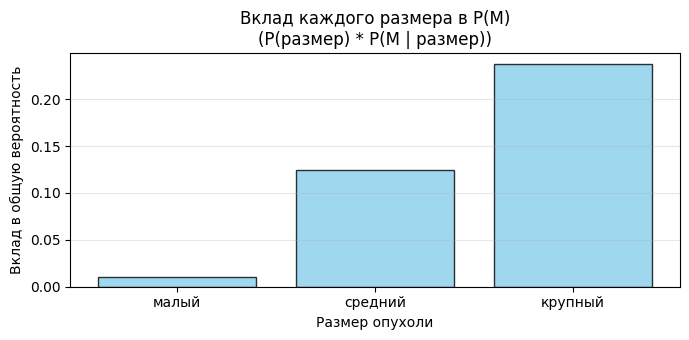

In [28]:
plt.figure(figsize=(7, 3.5))
plt.bar(order_size, contrib.values, color='skyblue', edgecolor='black', alpha=0.8)
plt.title('Вклад каждого размера в P(M)\n(P(размер) * P(M | размер))')
plt.xlabel('Размер опухоли')
plt.ylabel('Вклад в общую вероятность')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Формула полной вероятности даёт то же значение, что и прямой подсчёт. Наибольший вклад в $P(M)$ вносят крупные опухоли (0.2373 из 0.3726), хотя их доля среди пациентов (0.2478) меньше, чем доля средних (0.4552).

## 3. Теорема Байеса
---
Известно, что опухоль злокачественная. Какого она, скорее всего, размера? Нужно найти $P_M(H_i)$:

$$P_M(H_i) = \frac{P(H_i) \cdot P_{H_i}(M)}{P(M)}.$$

Вероятности $P(H_i)$ - априорные (до того, как узнали диагноз), $P_M(H_i)$ - апостериорные (после того, как узнали диагноз).

In [29]:
posterior = contrib / P_M
bayes_df = pd.DataFrame({'P(размер)': H, 'P(размер | M)': posterior})
print("Проверка прямым подсчётом по злокачественным опухолям:")
print(df.loc[df['malignant'], 'size'].value_counts(normalize=True).loc[order_size].round(4).to_dict())
bayes_df

Проверка прямым подсчётом по злокачественным опухолям:
{'малый': 0.0283, 'средний': 0.3349, 'крупный': 0.6368}


,P(размер),P(размер | M)
size,,
малый,0.2970,0.0283
средний,0.4552,0.3349
крупный,0.2478,0.6368


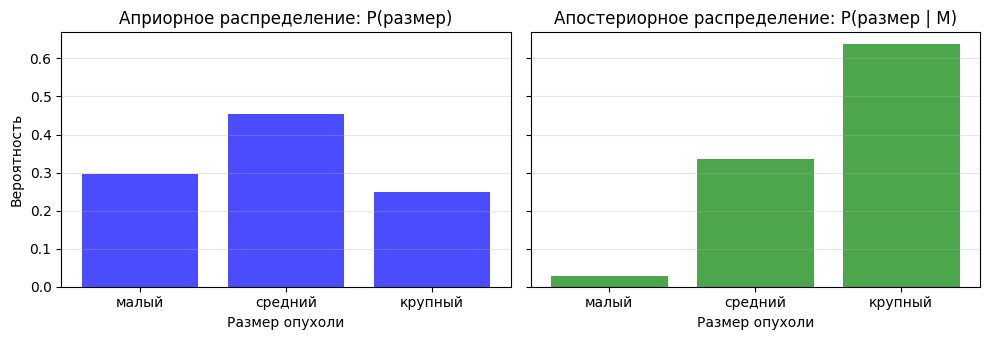

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

ax1.bar(order_size, bayes_df['P(размер)'], color='BLUE', alpha=0.7)
ax1.set_title('Априорное распределение: P(размер)')
ax1.set_ylabel('Вероятность')

ax2.bar(order_size, bayes_df['P(размер | M)'], color='GREEN', alpha=0.7)
ax2.set_title('Апостериорное распределение: P(размер | M)')

for ax in (ax1, ax2):
    ax.set_xlabel('Размер опухоли')
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Среди всех пациентов крупные опухоли составляют 24.8%, а среди злокачественных - уже 63.7%; доля малых опухолей падает с 29.7% до 2.8%. Узнав диагноз, мы «обновили» представление о размере опухоли.

## Вывод
---
* Условные вероятности показывают связь между признаками и диагнозом: вероятность злокачественной опухоли зависит от размера и вогнутости контура и изменяется от единиц процентов до почти 100%, тогда как безусловная вероятность $P(M) \approx 0.37$.
* Формула полной вероятности позволяет восстановить общую вероятность $P(M)$ по сценариям (размер опухоли), для каждого из которых вероятность считать проще.
* Теорема Байеса позволяет развернуть условие: по известному диагнозу оценить распределение размера опухоли.